In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ai4_tools as ai4

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, validation_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn import svm


data = "stroke-prediction.csv"
r = pd.read_csv(data)
raw = r.copy()

METRIC = "roc_auc"
def overview(d):
    numbers = d.select_dtypes("number")
    return pd.DataFrame({"type": d.dtypes.astype(str), "missing": d.isna().sum(),
                         "distinct": d.nunique(), "min": numbers.min(), "max": numbers.max()})
TARGET = "stroke"
df = raw.drop(columns="id")
df.loc[df["bmi"] > 80, "bmi"] = np.nan
df = df[df["gender"] != "Other"]
df = df.dropna(subset=[TARGET])

y = df[TARGET]
X = df.drop(columns=[TARGET])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Preprocessor. One-hot categorical, impute bmi, also flag missing bmi
numeric_cols = X.select_dtypes("number").columns.tolist()
text_cols = [c for c in X.columns if c not in numeric_cols]
preprocess_flag = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), text_cols),
])

# MY_FILE = "stroke-prediction.csv"
# raw = pd.read_csv(MY_FILE)

# TARGET = "stroke"
# DROP = ["id"]

# df = raw.drop(columns=DROP)
# y = df[TARGET]
# X = df.drop(columns=[TARGET])

# numeric_cols = X.select_dtypes("number").columns.tolist()
# text_cols = [c for c in X.columns if c not in numeric_cols]

# preprocess = ColumnTransformer([
#     ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
#     ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
#                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), text_cols),
# ])

C = 1.0  # SVM regularization parameter
models = {
    "SVC linear": svm.SVC(kernel="linear", C=C, class_weight = 'balanced'),
    "LinearSVC": svm.LinearSVC(C=C, max_iter=10000, class_weight = 'balanced'),
    "SVC rbf": svm.SVC(kernel="rbf", gamma=0.7, C=C, class_weight = 'balanced'),
    "SVC poly": svm.SVC(kernel="poly", degree=3, gamma="auto", C=C, class_weight = 'balanced'),
}

Xm_train, X_test, ym_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

def compare(models, X, y, cv, scoring=("roc_auc", "recall")):
    rows = []
    for name, model in models.items():
        pipe = Pipeline([("prep", preprocess_flag), ("model", model)])
        s = cross_validate(pipe, X, y, cv=cv, scoring=list(scoring), return_train_score=True)
        row = {"model": name}
        for m in scoring:
            row[m] = s["test_" + m].mean()
            row[m + " spread"] = s["test_" + m].std()
        row["training " + scoring[0]] = s["train_" + scoring[0]].mean()
        row["fit ms"] = 1000 * s["fit_time"].mean()
        row["score ms per 1000 rows"] = 1000 * s["score_time"].mean() / (len(X) / cv.get_n_splits()) * 1000
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").round(3)

results = compare(models, Xm_train, ym_train, cv)
results

,roc_auc,roc_auc spread,recall,recall spread,training roc_auc,fit ms,score ms per 1000 rows
model,,,,,,,
SVC linear,0.856,0.013,0.819,0.042,0.867,228.854,73.356
LinearSVC,0.857,0.014,0.824,0.034,0.869,22.776,22.154
SVC rbf,0.690,0.046,0.131,0.063,0.992,197.475,253.531
SVC poly,0.811,0.025,0.633,0.070,0.909,172.658,81.520


#### Searching for dial, starting with C

In [2]:
from sklearn.model_selection import GridSearchCV

METRIC = "roc_auc"
TUNE = "LinearSVC"
GRID = {"model__C": np.logspace(-4, 3, 8)}

pipe = Pipeline([("prep", preprocess_flag), ("model", models[TUNE])])

search = GridSearchCV(pipe, GRID, cv=cv, scoring=METRIC, return_train_score=True)
search.fit(Xm_train, ym_train)

grid_table = pd.DataFrame(search.cv_results_)[["params", "mean_train_score", "mean_test_score", "std_test_score"]]
print("best:", search.best_params_, " cross-validated {}: {:.4f}".format(METRIC, search.best_score_))

models[TUNE + ", tuned"] = search.best_estimator_.named_steps["model"]   # model only; compare() adds prep
grid_table.round(4)

best: {'model__C': np.float64(0.001)}  cross-validated roc_auc: 0.8586


,params,mean_train_score,mean_test_score,std_test_score
0,{'model__C': 0.0001},0.8569,0.8515,0.0208
1,{'model__C': 0.001},0.8671,0.8586,0.0160
2,{'model__C': 0.01},0.8690,0.8577,0.0144
3,{'model__C': 0.1},0.8692,0.8572,0.0140
4,{'model__C': 1.0},0.8692,0.8570,0.0141
5,{'model__C': 10.0},0.8692,0.8569,0.0141
6,{'model__C': 100.0},0.8692,0.8569,0.0141
7,{'model__C': 1000.0},0.8692,0.8569,0.0141


only a 0.001 improvement on roc_auc, so lets change gamma

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.metrics import make_scorer, fbeta_score

SCORING = {
    "f2": make_scorer(fbeta_score, beta=2),
    "recall": "recall",
    "precision": "precision",
    "roc_auc": "roc_auc",
    "avg_precision": "average_precision",
}

def tune(name, grid):
    """Grid-search one model from `models` inside the full pipeline, using CV on the training split."""
    pipe = Pipeline([("prep", preprocess_flag), ("model", models[name])])
    search = GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, refit=METRIC,
                          return_train_score=True, n_jobs=-1)
    search.fit(Xm_train, ym_train)

    cols = ["params", f"mean_train_{METRIC}"] + [f"mean_test_{m}" for m in SCORING] + [f"std_test_{METRIC}"]
    table = pd.DataFrame(search.cv_results_)[cols].sort_values(f"mean_test_{METRIC}", ascending=False)

    print(f"{name} best: {search.best_params_}")
    print(f"  cross-validated {METRIC}: {search.best_score_:.4f}")

    models[name + ", tuned"] = search.best_estimator_.named_steps["model"]
    return search, table.round(4)

In [6]:
Cs = np.logspace(-4, 3, 8)
weights = [None, "balanced"]
scalers = [StandardScaler(), RobustScaler(), MinMaxScaler()]

grid_linear = [
    # l2 + hinge only works with dual=True
    {"model__penalty": ["l2"], "model__loss": ["hinge"], "model__dual": [True],
     "model__C": Cs, "model__class_weight": weights, "prep__num__scale": scalers},
    # l2 + squared_hinge
    {"model__penalty": ["l2"], "model__loss": ["squared_hinge"], "model__dual": [False],
     "model__C": Cs, "model__class_weight": weights, "prep__num__scale": scalers},
    # l1 only works with squared_hinge and dual=False
    {"model__penalty": ["l1"], "model__loss": ["squared_hinge"], "model__dual": [False],
     "model__C": Cs, "model__class_weight": weights, "prep__num__scale": scalers},
]

search_lin, table_lin = tune("LinearSVC", grid_linear)
table_lin.head(10)

LinearSVC best: {'model__C': np.float64(0.01), 'model__class_weight': 'balanced', 'model__dual': False, 'model__loss': 'squared_hinge', 'model__penalty': 'l1', 'prep__num__scale': StandardScaler()}
  cross-validated roc_auc: 0.8595


,params,mean_train_roc_auc,mean_test_f2,mean_test_recall,mean_test_precision,mean_test_roc_auc,mean_test_avg_precision,std_test_roc_auc
111,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.8662,0.4137,0.8244,0.1385,0.8595,0.2353,0.0142
57,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.8671,0.4203,0.8294,0.1417,0.8586,0.2197,0.0160
15,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.8668,0.4126,0.8294,0.1373,0.8582,0.2289,0.0141
63,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.8690,0.4293,0.8294,0.1467,0.8577,0.2330,0.0144
71,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.8695,0.4293,0.8294,0.1467,0.8577,0.2306,0.0144
117,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.8691,0.4298,0.8294,0.1470,0.8576,0.2337,0.0140
33,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.8667,0.4173,0.8194,0.1410,0.8575,0.2446,0.0129
119,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.8688,0.4271,0.8244,0.1460,0.8575,0.2324,0.0141
118,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.8688,0.4285,0.8294,0.1462,0.8573,0.2335,0.0140
64,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.8682,0.4241,0.8294,0.1437,0.8573,0.2206,0.0144


In [7]:
grid_rbf = {
    "model__C": np.logspace(-3, 3, 7),
    "model__gamma": ["scale", 0.001, 0.01, 0.1, 1],
    "model__class_weight": [None, "balanced"],
}

search_rbf, table_rbf = tune("SVC rbf", grid_rbf)
table_rbf.head(10)

SVC rbf best: {'model__C': np.float64(10.0), 'model__class_weight': 'balanced', 'model__gamma': 0.001}
  cross-validated roc_auc: 0.8582


,params,mean_train_roc_auc,mean_test_f2,mean_test_recall,mean_test_precision,mean_test_roc_auc,mean_test_avg_precision,std_test_roc_auc
46,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.8687,0.4142,0.8194,0.1393,0.8582,0.2479,0.0148
37,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.8778,0.4122,0.8144,0.1387,0.8581,0.2715,0.0141
27,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.8658,0.4206,0.8344,0.1413,0.8571,0.2206,0.0189
36,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.8647,0.4205,0.8294,0.1420,0.8563,0.2128,0.0174
56,"{'model__C': 100.0, 'model__class_weight': 'ba...",0.8779,0.4201,0.8094,0.1438,0.8559,0.2732,0.0142
26,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.8501,0.4062,0.7442,0.1448,0.8454,0.1923,0.0218
28,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.8927,0.4035,0.8345,0.1317,0.8439,0.1963,0.0197
17,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.8486,0.3994,0.6991,0.1476,0.8439,0.1907,0.0228
25,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.8932,0.4035,0.8345,0.1317,0.8437,0.1954,0.0197
6,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.8464,0.1637,0.8000,0.0391,0.8415,0.1924,0.0236


In [8]:
grid_poly = {
    "model__degree": [2, 3, 4],
    "model__coef0": [0, 1],
    "model__C": [0.0001, 0.001, 1, 10],          # large C with poly can take a very long time
    "model__gamma": ["scale", 0.01, 0.1],
    "model__class_weight": ["balanced"],
}

search_poly, table_poly = tune("SVC poly", grid_poly)
table_poly.head(10)

SVC poly best: {'model__C': 1, 'model__class_weight': 'balanced', 'model__coef0': 1, 'model__degree': 2, 'model__gamma': 0.01}
  cross-validated roc_auc: 0.8590


,params,mean_train_roc_auc,mean_test_f2,mean_test_recall,mean_test_precision,mean_test_roc_auc,mean_test_avg_precision,std_test_roc_auc
46,"{'model__C': 1, 'model__class_weight': 'balanc...",0.8743,0.4183,0.8244,0.1410,0.8590,0.2781,0.0149
49,"{'model__C': 1, 'model__class_weight': 'balanc...",0.8812,0.4145,0.7942,0.1425,0.8546,0.2674,0.0132
52,"{'model__C': 1, 'model__class_weight': 'balanc...",0.8877,0.4172,0.7892,0.1448,0.8493,0.2633,0.0126
30,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.8590,0.3978,0.6235,0.1627,0.8470,0.2198,0.0210
32,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.8587,0.3960,0.6185,0.1626,0.8469,0.2187,0.0210
27,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.8517,0.3916,0.6135,0.1604,0.8468,0.2015,0.0211
29,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.8516,0.3913,0.6135,0.1602,0.8466,0.2011,0.0212
64,"{'model__C': 10, 'model__class_weight': 'balan...",0.8869,0.4146,0.7841,0.1440,0.8462,0.2648,0.0135
37,"{'model__C': 1, 'model__class_weight': 'balanc...",0.8583,0.3921,0.6235,0.1580,0.8447,0.2242,0.0229
35,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.8723,0.3870,0.6083,0.1580,0.8438,0.2306,0.0191


In [9]:
for name, s in [("LinearSVC", search_lin), ("SVC rbf", search_rbf), ("SVC poly", search_poly)]:
    best_C = s.best_params_["model__C"]
    grid_Cs = sorted({p["model__C"] for p in s.cv_results_["params"]})
    if best_C in (grid_Cs[0], grid_Cs[-1]):
        print(f"{name}: best C={best_C} is at the edge of the grid; widen the range")

In [10]:
results = compare(models, Xm_train, ym_train, cv)
results

,roc_auc,roc_auc spread,recall,recall spread,training roc_auc,fit ms,score ms per 1000 rows
model,,,,,,,
SVC linear,0.856,0.013,0.819,0.042,0.867,305.333,90.645
LinearSVC,0.857,0.014,0.824,0.034,0.869,29.180,30.460
SVC rbf,0.690,0.046,0.131,0.063,0.992,214.492,284.720
SVC poly,0.811,0.025,0.633,0.070,0.909,239.047,109.243
"LinearSVC, tuned",0.860,0.014,0.824,0.041,0.866,39.202,39.695
"SVC rbf, tuned",0.858,0.015,0.819,0.042,0.869,279.543,363.820
"SVC poly, tuned",0.859,0.015,0.824,0.034,0.874,176.821,87.506


### Proceeding with LinearSVC, tuned. Let's try adjusting the threshold to see if we can get better recall

In [11]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score

best = search_lin.best_estimator_
final = Pipeline([
    ("prep", best.named_steps["prep"]),
    ("model", CalibratedClassifierCV(best.named_steps["model"], method="sigmoid", cv=5)),
])

proba = cross_val_predict(final, Xm_train, ym_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0, 0.1, 0.01):
    p = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(ym_train, p, zero_division=0),
                 "recall": recall_score(ym_train, p),
                 "share flagged": p.mean()})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,share flagged
0,0.00,0.049,1.000,1.000
1,0.01,0.076,0.990,0.636
2,0.02,0.094,0.950,0.490
3,0.03,0.113,0.915,0.396
4,0.04,0.129,0.869,0.329
5,0.05,0.142,0.809,0.277
6,0.06,0.158,0.779,0.240
7,0.07,0.171,0.754,0.215
8,0.08,0.178,0.709,0.194
9,0.09,0.189,0.673,0.174


              precision    recall  f1-score   support

           0       0.99      0.70      0.82      3888
           1       0.13      0.86      0.22       199

    accuracy                           0.71      4087
   macro avg       0.56      0.78      0.52      4087
weighted avg       0.95      0.71      0.79      4087

test set at threshold 0.04: precision 0.129, recall 0.864


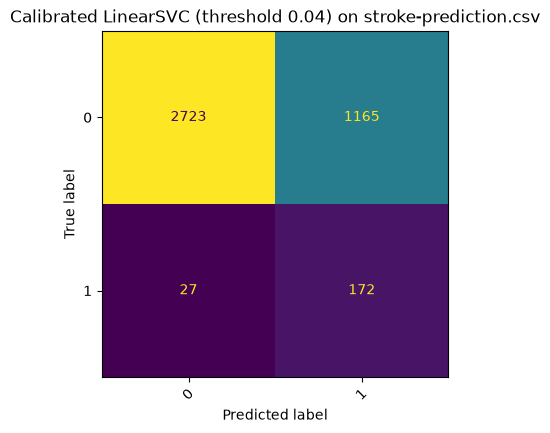

In [13]:
THRESHOLD = 0.04

final.fit(Xm_train, ym_train)

p_train = (final.predict_proba(Xm_train)[:, 1] >= THRESHOLD).astype(int)
print(classification_report(ym_train, p_train, zero_division=0))
print("test set at threshold {}: precision {:.3f}, recall {:.3f}".format(
    THRESHOLD, precision_score(ym_train, p_train, zero_division=0), recall_score(ym_train, p_train)))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(ym_train, p_train, ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title(f"Calibrated LinearSVC (threshold {THRESHOLD}) on " + data)
plt.show()

In [ ]:
final
print(final)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'hypertension',
                                                   'heart_disease',
                                                   'avg_glucose_level',
                                                   'bmi']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                          